# 3. Kündigungen vorhersagen

Ziel: Logistische Regression und Random Forest mit identischem Testsatz vergleichen. Imputation, Encoding und Skalierung werden nur auf Trainingsdaten gelernt. Die Modelllogik wird mit dem Dashboard geteilt.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Notebook im Projektordner oder in notebooks/ starten.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import pandas as pd

from src.churn import load_churn, train_churn_model, classification_metrics

data = load_churn()
result = train_churn_model(data)
print(f"Trainingskunden: {len(data) - len(result['y_test'])}; Testkunden: {len(result['y_test'])}")
print(f"Mehrheits-Baseline: {result['baseline_accuracy']:.2%}")
pd.Series(result["metrics"], name="Logistische Regression")

Trainingskunden: 5634; Testkunden: 1409
Mehrheits-Baseline: 73.46%
Out[0]: 
Accuracy     0.806955
Precision    0.658385
Recall       0.566845
F1-Score     0.609195
ROC-AUC      0.841585
Name: Logistische Regression, dtype: float64


`stratify` erhält die Klassenanteile näherungsweise. `random_state=42` macht den Split wiederholbar. Der Testsatz wird nur für die Auswertung verwendet. `max_iter=1000` ist eine Obergrenze für Optimierungsschritte, kein Genauigkeitsziel.

In [3]:
features = data.drop(columns=["customerID", "Churn"])
x_train, x_test, y_train, y_test = train_test_split(
    features, data["Churn"], test_size=0.2, random_state=42, stratify=data["Churn"]
)
forest = clone(result["model"])
forest.set_params(classifier=RandomForestClassifier(n_estimators=100, random_state=42))
forest.fit(x_train, y_train)
forest_metrics = classification_metrics(
    y_test, forest.predict(x_test), forest.predict_proba(x_test)[:, 1]
)
comparison = pd.DataFrame({"Logistische Regression": result["metrics"], "Random Forest": forest_metrics})
comparison

Out[0]: 
           Logistische Regression  Random Forest
Accuracy                 0.806955       0.785664
Precision                0.658385       0.621622
Recall                   0.566845       0.491979
F1-Score                 0.609195       0.549254
ROC-AUC                  0.841585       0.824450


Der Forest nutzt dieselbe Vorverarbeitung für einen nachvollziehbaren Vergleich. Bäume benötigen normalerweise keine Skalierung. Accuracy zählt alle richtigen Vorhersagen; Precision bewertet die als Kündiger markierten Kunden, Recall die tatsächlich gekündigten Kunden. F1 kombiniert Precision und Recall. ROC-AUC bewertet die Rangfolge der Scores über Entscheidungsschwellen hinweg.

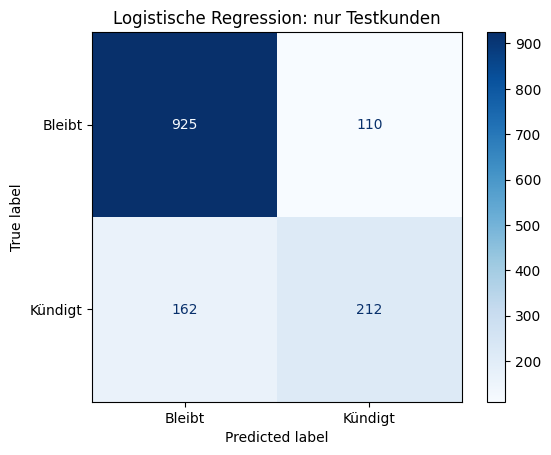

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(result["cm"], display_labels=["Bleibt", "Kündigt"]).plot(cmap="Blues")
plt.title("Logistische Regression: nur Testkunden")
plt.show()

StandardScaler berechnet `(Wert − Trainingsmittelwert) / Trainingsstandardabweichung`. Die Ergebnisse sind nicht auf −3 bis +3 begrenzt. Die Risikogrenzen im Dashboard sind Darstellungsregeln; unkalibrierte Scores sind keine garantierten Kündigungswahrscheinlichkeiten. Ein einzelner Split reicht noch nicht für eine belastbare allgemeine Modellwahl.